# Sprint 2 — Ingeniería de características y modelo base
**Proyecto:** Modelo Predictivo de Segmentación de Mercado y Propensión a la Matrícula · Unicervantes

**Pedido del docente (Semana 2):** entregar *la misma tabla de datos con columnas nuevas y útiles* (por ejemplo,
"¿Aplica a Beca Mi Vocación? Sí/No" o "Promedio estimado"; también `probabilidad_acceso_beca` y
`segmento_rendimiento_icfes`) y *un cálculo muy sencillo (modelo base) que sirva de punto de comparación*.

| Sección | Contenido |
|---|---|
| 1 | Datos y partición temporal (entrenamiento, validación, prueba y campaña) |
| 2 | Lo que se aprende SOLO del entrenamiento (sin fuga de datos) |
| 3 | Las 15 columnas nuevas |
| 4 | Segmentación de mercado con k-means |
| 5 | Relación de las columnas nuevas con la matrícula |
| 6 | Modelo base y su error |

In [1]:
import sys
import warnings
from pathlib import Path

# Raíz del repositorio: se sube de carpeta hasta encontrar config/reglas_negocio.yaml
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "reglas_negocio.yaml").exists())
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore")
EN_COLAB = False
SPRINTS = RAIZ / "sprints"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#1B365D", "#E07B39", "#9AA5B1"

## 1. Datos y partición temporal
Los datos se dividen por **tiempo**, no al azar: se aprende con el pasado y se evalúa con el futuro, como pasará en la
realidad. La campaña 2027-1 no tiene resultado (se predice); su resultado real está sellado hasta el Sprint 5.

| Conjunto | Periodos | Para qué |
|---|---|---|
| ENTRENAMIENTO | 2024-1 a 2025-2 | Aprender tasas, regresión, k-means y modelos |
| VALIDACION | 2026-1 | Elegir hiperparámetros (Sprint 3) |
| PRUEBA | 2026-2 | Medir el error final, una sola vez |
| CAMPANA | 2027-1 | Lo que el modelo predice |

In [3]:
import caracteristicas as ca
import flujo
import modelado as mo

# Lee las tablas planas por la API de Supabase (solo lectura) y construye las columnas del Sprint 2
f = flujo.cargar_y_construir("supabase" if EN_COLAB else "auto")
d, p, ref, cfg = f["inscritos"], f["permanencia"], f["referencias"], ca.configuracion()
print("Origen de los datos:", f["origen"])
print(f"Inscritos: {len(d):,} · matriculados con el primer semestre cerrado: {len(p):,}")
print(d["particion"].value_counts().to_string())

Origen de los datos: Supabase (API de solo lectura)
Inscritos: 2,991 · matriculados con el primer semestre cerrado: 835
particion
ENTRENAMIENTO    1310
PRUEBA            761
VALIDACION        504
CAMPANA           416


## 2. Lo que se aprende solo del entrenamiento
Si las tasas o los grupos se calcularan con todos los datos, la validación y la prueba "verían" información del futuro
(fuga de datos) y el error saldría engañosamente bajo. Por eso `ajustar_referencias` usa **solo** el entrenamiento.

In [4]:
tabla = ref["tabla_acceso_beca"].copy()
tabla["probabilidad"] = tabla["probabilidad"].round(3)
print("Probabilidad de acceso a beca por grupo de requisitos (suavizado de Laplace: (k + 1) / (n + 2)):")
display(tabla)
r = ref["regresion_promedio"]
print("\nRegresión del promedio del 1er semestre (mínimos cuadrados, matriculados de entrenamiento):")
print("  promedio = " + " + ".join(f"{v:.4f}·{k}" if k != "intercepto" else f"{v:.3f}" for k, v in r["coeficientes"].items()))
print(f"  R² = {r['r2']:.3f} · error típico = {r['error_tipico']:.2f} puntos · n = {r['n']}")

Probabilidad de acceso a beca por grupo de requisitos (suavizado de Laplace: (k + 1) / (n + 2)):


,n,con_beca,probabilidad
MI_VOCACION_3,264,65,0.248
MI_VOCACION_4,291,220,0.754
MI_VOCACION_5,159,148,0.925
SABER_11,268,255,0.948
SIN_REQUISITOS,328,0,0.000



Regresión del promedio del 1er semestre (mínimos cuadrados, matriculados de entrenamiento):
  promedio = 1.701 + 0.0024·punt_global + 0.3643·promedio_acumulado_colegio + -0.0559·estrato_bajo
  R² = 0.170 · error típico = 0.40 puntos · n = 621


## 3. Las columnas nuevas
Cada columna responde una pregunta de negocio. Las que dependen de una regla (Sí/No de becas, bandas del ICFES,
valor neto) se calculan igual para todos; las que dependen de datos usan lo aprendido en la sección 2.

In [5]:
print(f"Columnas nuevas: {len(ca.NUEVAS)}")
display(pd.DataFrame({"columna": list(ca.DICCIONARIO), "qué es": list(ca.DICCIONARIO.values())}))
muestra = d[["inscripcion_id", "periodo", "punt_global", "aplica_beca_saber11", "aplica_beca_mi_vocacion",
             "probabilidad_acceso_beca", "segmento_rendimiento_icfes", "promedio_acumulado_colegio",
             "promedio_estimado_universidad", "valor_neto_primer_semestre", "ahorro_beca_primer_semestre", "zona_distancia",
             "segmento_mercado"]]
display(muestra.head(8))
print("¿Aplica a Mi Vocación?", d["aplica_beca_mi_vocacion"].value_counts().to_dict(),
      "· ¿Aplica a Saber 11?", d["aplica_beca_saber11"].value_counts().to_dict())
print("Nulos en las columnas nuevas:", int(d[ca.NUEVAS].isna().sum().sum()))

Columnas nuevas: 15


,columna,qué es
0,particion,Conjunto temporal: ENTRENAMIENTO (2024-1 a 202...
1,aplica_beca_saber11,Sí/No: puntaje global Saber 11 ≥ 310 (requisit...
2,aplica_beca_mi_vocacion,Sí/No: presentó entrevista y su puntaje vocaci...
3,probabilidad_acceso_beca,Probabilidad de recibir alguna beca según los ...
4,segmento_rendimiento_icfes,"BAJO (< 250), MEDIO (250-309), ALTO (310-349: ..."
5,promedio_estimado_universidad,Promedio esperado en el 1er semestre (regresió...
6,brecha_colegio_vs_icfes,z(promedio del colegio) − z(Saber 11): positiv...
7,ahorro_beca_primer_semestre,Cuánto le ahorra la beca en el 1er semestre (t...
8,log_distancia,Logaritmo natural de la distancia por vías des...
9,zona_distancia,Distancia por vías desde la dirección: CERCA (...


,inscripcion_id,periodo,punt_global,aplica_beca_saber11,aplica_beca_mi_vocacion,probabilidad_acceso_beca,segmento_rendimiento_icfes,promedio_acumulado_colegio,promedio_estimado_universidad,valor_neto_primer_semestre,ahorro_beca_primer_semestre,zona_distancia,segmento_mercado
0,1,2026-1,325,Sí,Sí,0.948,ALTO,4.360,4.020,3439800,1474200,CERCA,"S2: Buen puntaje ICFES, colegio privado"
1,2,2025-1,298,No,No,0.000,MEDIO,3.830,3.820,4658000,0,MEDIA,"S2: Buen puntaje ICFES, colegio privado"
2,3,2025-2,229,No,Sí,0.248,BAJO,4.050,3.730,4658000,0,MEDIA,"S5: Aspirantes mayores, viven cerca del campus"
3,4,2026-2,256,No,No,0.000,MEDIO,3.570,3.570,4914000,0,CERCA,"S1: Colegio público, viven cerca del campus"
4,5,2026-2,341,Sí,Sí,0.948,ALTO,3.320,3.740,3439800,1474200,CERCA,"S4: Colegio privado, notas bajas en el colegio"
5,6,2026-2,235,No,No,0.000,BAJO,4.150,3.780,4950000,0,MEDIA,"S1: Colegio público, viven cerca del campus"
6,7,2026-2,261,No,No,0.000,MEDIO,4.080,3.760,4914000,0,LEJOS,"S3: Viven lejos del campus, estrato más bajo"
7,8,2025-1,274,No,Sí,0.925,MEDIO,4.140,3.870,3260600,1397400,CERCA,"S2: Buen puntaje ICFES, colegio privado"


¿Aplica a Mi Vocación? {'Sí': 2067, 'No': 924} · ¿Aplica a Saber 11? {'No': 2360, 'Sí': 631}
Nulos en las columnas nuevas: 0


## 4. Segmentación de mercado con k-means
k-means agrupa a los aspirantes por parecido en su perfil (estrato, distancia, ICFES, promedio del colegio, edad y tipo
de colegio). No se usa la media ICFES del colegio porque Admisiones no suele tener ese dato. Antes se **estandarizan** las variables (restar la media y dividir por la desviación), para que ninguna pese
más solo por estar en otra escala. El número de grupos k se elige con la **silueta**: qué tan cerca está cada aspirante
de su grupo frente al grupo vecino (de −1 a 1; más alto es mejor).

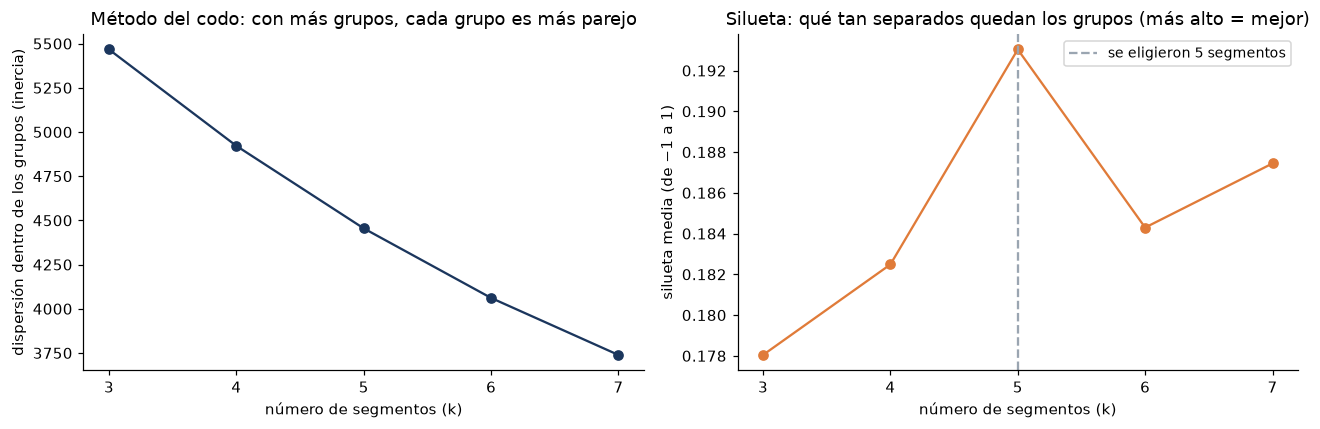

Mapa de los segmentos: las 6 variables proyectadas en 2 dimensiones (componentes principales).


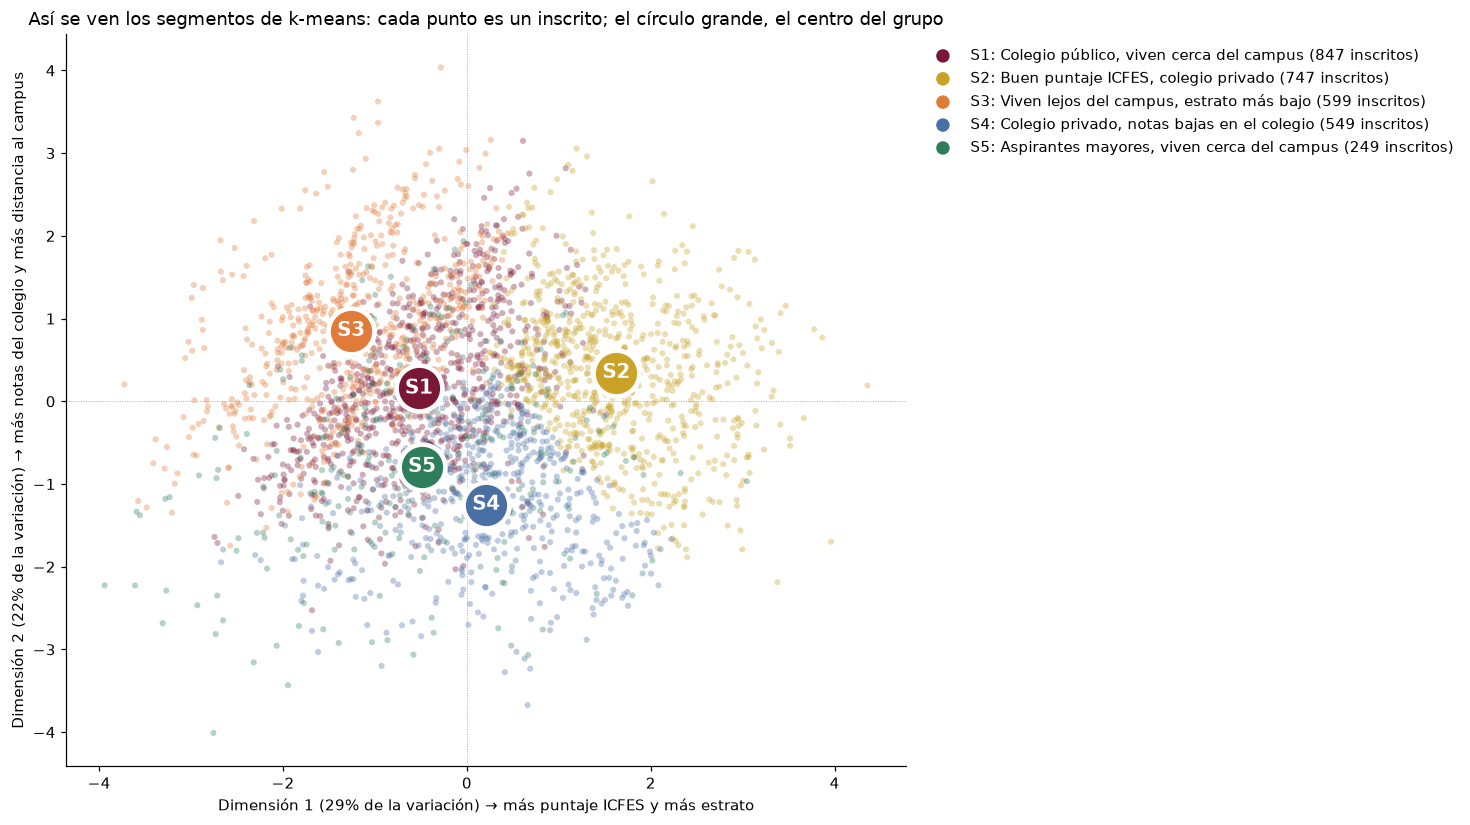

Cada segmento se nombra por los 2 rasgos en que más se aleja del promedio de los inscritos.


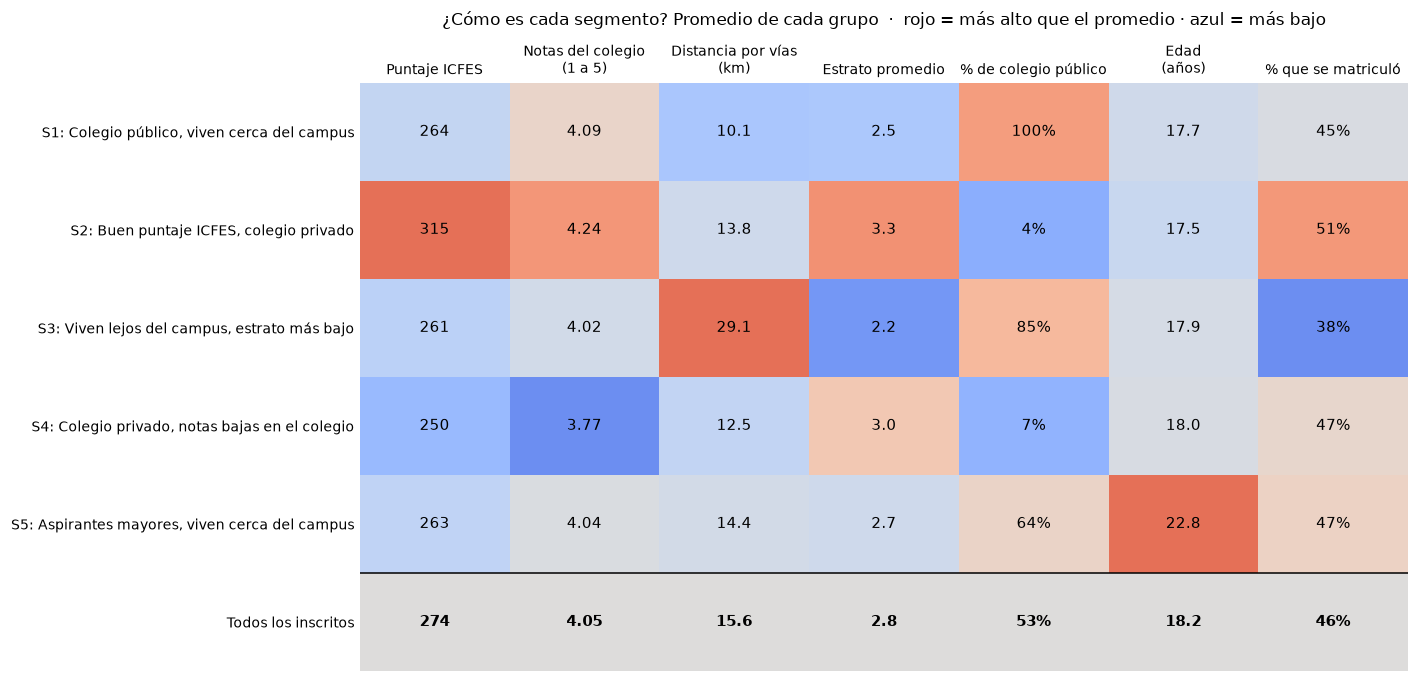

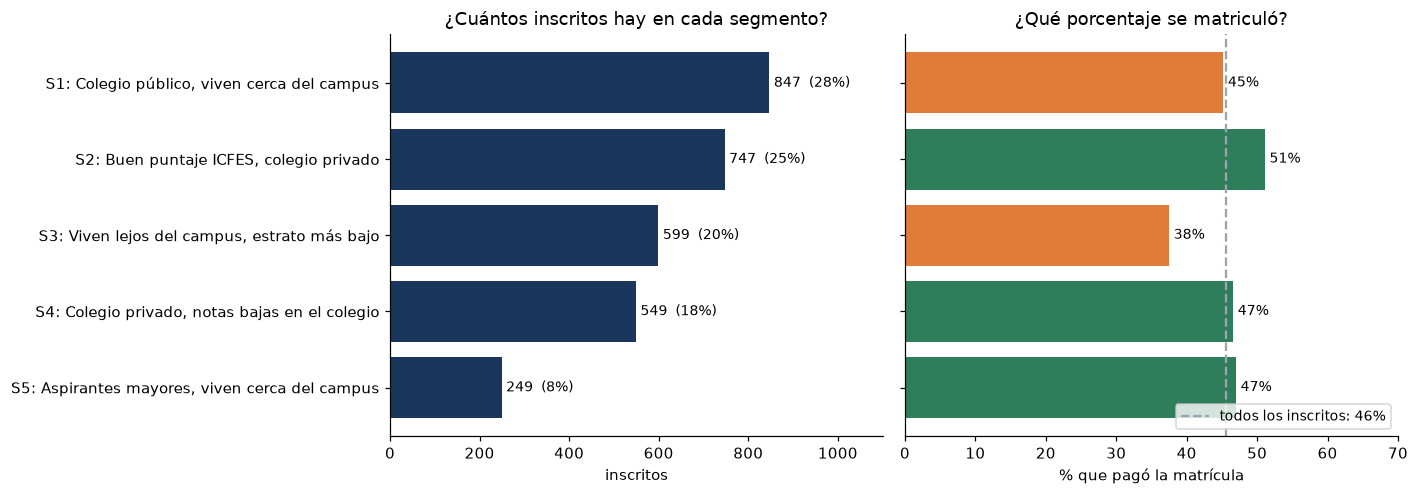

Tabla de segmentos (promedios reales de cada grupo):


,Inscritos,% del total,% que se matriculó,Puntaje ICFES,Notas del colegio (1 a 5),Distancia por vías (km),Estrato promedio,% de colegio público,Edad (años)
Segmento de mercado,,,,,,,,,
"S1: Colegio público, viven cerca del campus",847,28.300,45.200,264.000,4.090,10.100,2.500,100.000,17.700
"S2: Buen puntaje ICFES, colegio privado",747,25.000,51.100,315.000,4.240,13.800,3.300,4.000,17.500
"S3: Viven lejos del campus, estrato más bajo",599,20.000,37.500,261.000,4.020,29.100,2.200,85.000,17.900
"S4: Colegio privado, notas bajas en el colegio",549,18.400,46.600,250.000,3.770,12.500,3.000,7.000,18.000
"S5: Aspirantes mayores, viven cerca del campus",249,8.300,47.000,263.000,4.040,14.400,2.700,64.000,22.800
Todos los inscritos,2991,100.000,45.600,274.000,4.050,15.600,2.800,53.000,18.200


In [6]:
import graficas_sprint2 as gr


def ver(fig):
    """Muestra la figura en su lugar (antes de las tablas que siguen) y la cierra."""
    display(fig)
    plt.close(fig)


ver(gr.eleccion_k(ref))
print("Mapa de los segmentos: las 6 variables proyectadas en 2 dimensiones (componentes principales).")
ver(gr.mapa_segmentos(d, ref))
print("Cada segmento se nombra por los 2 rasgos en que más se aleja del promedio de los inscritos.")
ver(gr.perfil_segmentos(d))
ver(gr.tamano_y_matricula(d))
print("Tabla de segmentos (promedios reales de cada grupo):")
display(ca.tabla_segmentos(d))

**Cómo leer el mapa.** k-means usa 6 variables a la vez, así que no se puede dibujar directamente. El mapa las resume en
2 dimensiones (componentes principales): cada punto es un inscrito, el color es el segmento que le asignó k-means y el
círculo grande es el centro del grupo. Los grupos se tocan en los bordes: por eso la silueta es baja.

**Cómo leer los nombres.** Cada segmento se nombra con los **2 rasgos en que más se diferencia del promedio**
de todos los inscritos. Los nombres son **relativos**: "viven cerca del campus" quiere decir más cerca que el promedio
(15,6 km por vías), no a menos de cierta distancia; "colegio público" quiere decir que casi todos vienen de colegios
oficiales (públicos). La tabla muestra los valores reales para comprobarlo.

| Segmento | En palabras sencillas |
|---|---|
| S1: Colegio público, viven cerca del campus | El grupo más grande: egresados de colegios públicos que viven relativamente cerca |
| S2: Buen puntaje ICFES, colegio privado | Colegios privados con el mejor ICFES (muchos aplican a la beca Saber 11); el que más se matricula |
| S3: Viven lejos del campus, estrato más bajo | Viven a unos 29 km por vías y son de estratos 1 y 2; el que menos se matricula |
| S4: Colegio privado, notas bajas en el colegio | Colegios privados con notas e ICFES por debajo del promedio |
| S5: Aspirantes mayores, viven cerca del campus | Unos 23 años en promedio: no vienen directo del colegio |

**Qué tan buenos son los grupos.** La silueta es baja (cerca de 0,2): los aspirantes no forman grupos muy separados,
algo común en datos de personas. Aun así, los segmentos tienen perfiles con sentido de negocio y tasas de matrícula
distintas (del 38% al 51%), por eso sirven para orientar la estrategia de captación (Sprint 5).

## 5. Relación de las columnas nuevas con la matrícula (entrenamiento)

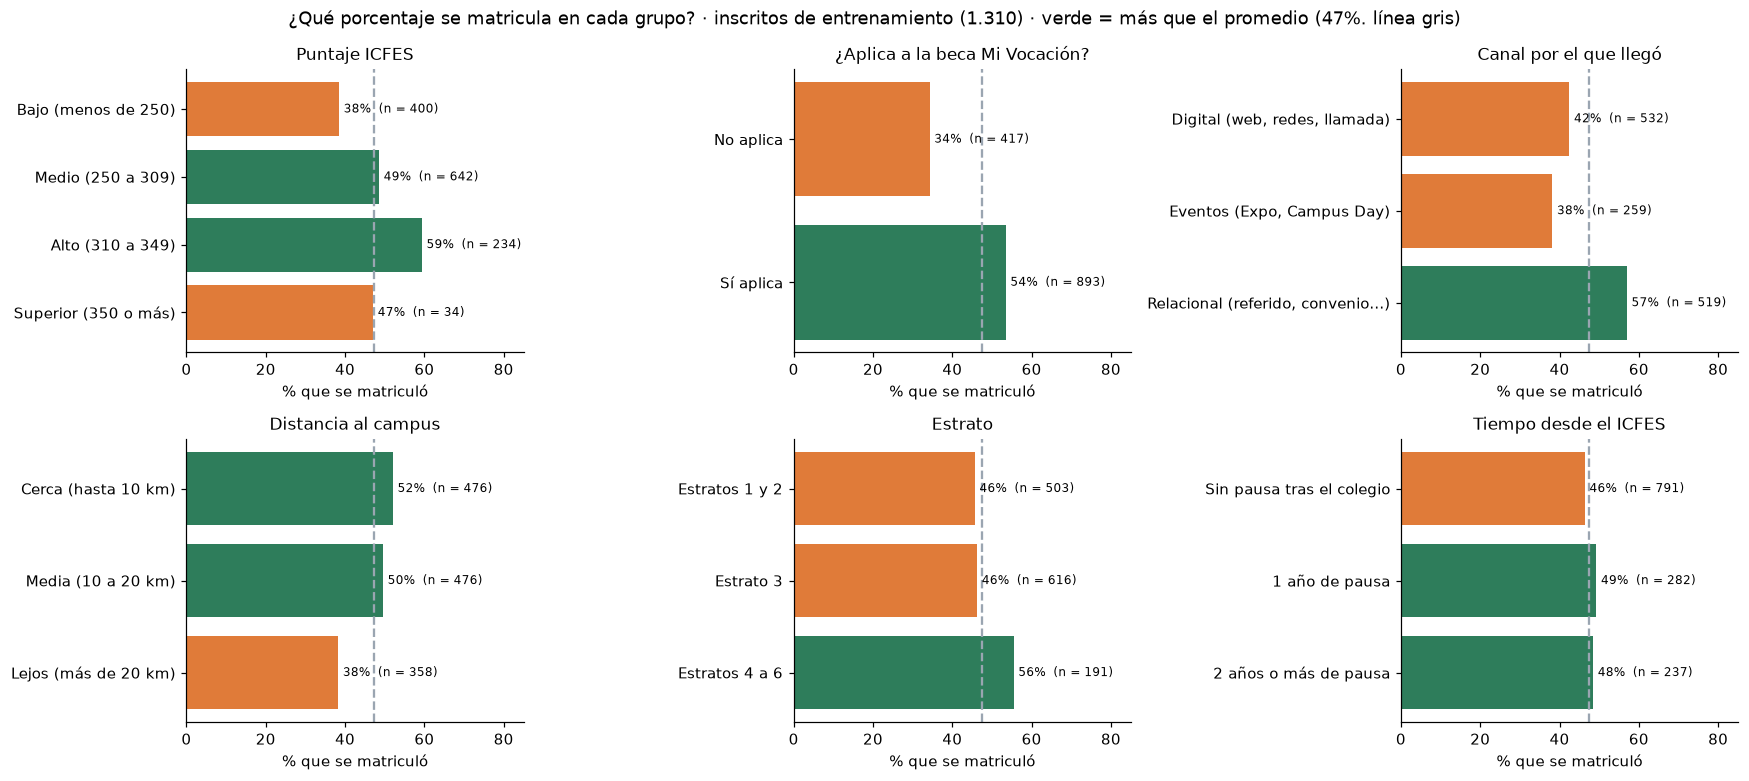

,Característica,Grupo,Inscritos,% que se matriculó
0,Puntaje ICFES,Bajo (menos de 250),400,38.500
1,Puntaje ICFES,Medio (250 a 309),642,48.600
2,Puntaje ICFES,Alto (310 a 349),234,59.400
3,Puntaje ICFES,Superior (350 o más),34,47.100
4,¿Aplica a la beca Mi Vocación?,No aplica,417,34.300
5,¿Aplica a la beca Mi Vocación?,Sí aplica,893,53.500
6,Canal por el que llegó,"Digital (web, redes, llamada)",532,42.500
7,Canal por el que llegó,"Eventos (Expo, Campus Day)",259,38.200
8,Canal por el que llegó,"Relacional (referido, convenio…)",519,57.000
9,Distancia al campus,Cerca (hasta 10 km),476,52.100


,correlación con la matrícula
"Probabilidad de recibir alguna beca según los requisitos que cumple (frecuencia histórica del entrenamiento, con suavizado de Laplace)",0.241
valor_neto_primer_semestre,-0.259
Logaritmo natural de la distancia por vías desde la dirección hasta el campus (S-44; reduce la cola larga),-0.105
z(promedio del colegio) − z(Saber 11): positivo = rinde más en el colegio que en el examen,-0.022
"Promedio esperado en el 1er semestre (regresión lineal con Saber 11, promedio del colegio y estrato bajo)",0.155


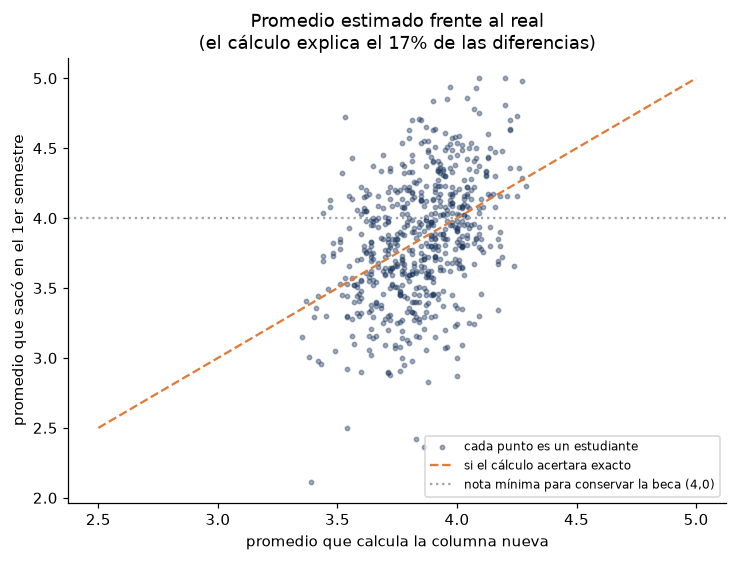

In [7]:
ent = flujo.conjunto(d, "ENTRENAMIENTO")
columnas = ["segmento_rendimiento_icfes", "aplica_beca_mi_vocacion", "canal_agrupado", "zona_distancia", "estrato_grupo",
            "rezago_saber11"]
ver(gr.matricula_por_grupo(ent, columnas))
display(gr.tabla_matricula_por_grupo(ent, columnas))
correl = ent[["probabilidad_acceso_beca", "valor_neto_primer_semestre", "log_distancia", "brecha_colegio_vs_icfes",
              "promedio_estimado_universidad"]].corrwith(ent["matriculado"].astype(float))
display(correl.rename(ca.DICCIONARIO).round(3).rename("correlación con la matrícula").to_frame())
p_ent = flujo.conjunto(p, "ENTRENAMIENTO")     # matriculados de entrenamiento, ya con las columnas nuevas
ver(gr.promedio_estimado(p_ent, ref["regresion_promedio"]["r2"]))

**Lectura.**
- El segmento ICFES ALTO (310-349) se matricula más que el SUPERIOR (≥ 350): los puntajes muy altos tienen más
  opciones puesto a que las universidades los buscan. Es la "U invertida" que el modelo deberá captar.
- Quien aplica a Mi Vocación se matricula más: la beca baja el precio.
- Los canales relacionales (referido, inmersión, convenio) convierten más que los eventos y lo digital.
- La matrícula baja con la distancia al campus (por vías, desde la dirección de cada inscrito).

## 6. Modelo base: el "cálculo sencillo" para comparar
Para cada inscrito se predice la **tasa histórica de matrícula de su grupo** (beca × canal agrupado), aprendida en el
entrenamiento. Si un grupo tiene pocos casos, su tasa se acerca a la de su beca:

`tasa = (matriculados + m · tasa de la beca) / (inscritos + m)`, con m = 10.

Se predice "se matricula" si la tasa es ≥ 50%. El **error %** es el porcentaje de inscritos mal clasificados. Se compara
con la referencia mínima: decir siempre "no se matricula".

inscritos  matriculados  tasa_cruda  tasa_suavizada
beca        canal_agrupado                                                     
MI_VOCACION DIGITAL               170        91.000       0.535           0.539
            EVENTO                 71        35.000       0.493           0.506
            RELACIONAL            192       135.000       0.703           0.698
NINGUNA     DIGITAL               252        69.000       0.274           0.276
            EVENTO                138        39.000       0.283           0.286
            RELACIONAL            232       100.000       0.431           0.427
SABER_11    DIGITAL               110        66.000       0.600           0.599
            EVENTO                 50        25.000       0.500           0.515
            RELACIONAL             95        61.000       0.642           0.637

,n,error_pct,auc_roc,brier
Modelo base · VALIDACION,504.000,37.698,0.646,0.230
Clase mayoritaria · VALIDACION,504.000,42.460,0.500,0.247
Modelo base · PRUEBA,761.000,41.656,0.615,0.241
Clase mayoritaria · PRUEBA,761.000,44.415,0.500,0.248


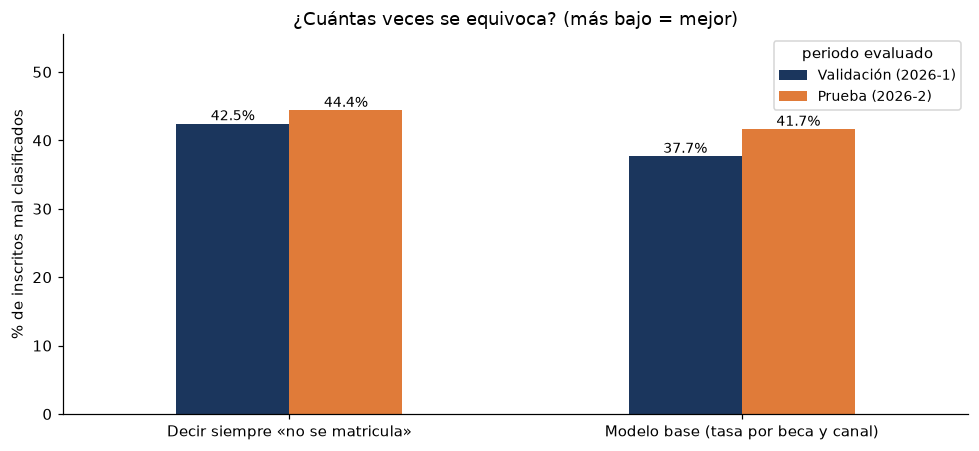


El modelo base se equivoca en el 41.7% de los inscritos de 2026-2; decir siempre 'no se matricula' se equivoca en el 44.4%. Este es el punto de comparación del Sprint 3.


In [8]:
ent = flujo.conjunto(d, "ENTRENAMIENTO")
base = mo.ModeloBase(m=cfg["caracteristicas"]["peso_previo_modelo_base"]).fit(ent, ent["matriculado"])
mayoria = mo.ClaseMayoritaria().fit(ent, ent["matriculado"])
display(base.tabla_.round(3))
resultados = {}
for conj in ["VALIDACION", "PRUEBA"]:
    X = flujo.conjunto(d, conj)
    resultados[f"Modelo base · {conj}"] = mo.metricas(X["matriculado"], base.predict_proba(X)[:, 1])
    resultados[f"Clase mayoritaria · {conj}"] = mo.metricas(X["matriculado"], mayoria.predict_proba(X)[:, 1])
tabla = mo.tabla_metricas(resultados)
display(tabla[["n", "error_pct", "auc_roc", "brier"]])
metr = pd.DataFrame({(m, c): v for (m, c), v in [(("modelo_base" if k.startswith("Modelo") else "clase_mayoritaria",
                     k.split(" · ")[1]), v) for k, v in resultados.items()]}).T.astype(float)
ver(gr.error_modelo_base(metr))
b = resultados["Modelo base · PRUEBA"]
print(f"\nEl modelo base se equivoca en el {b['error_pct']:.1f}% de los inscritos de 2026-2; decir siempre 'no se matricula' "
      f"se equivoca en el {resultados['Clase mayoritaria · PRUEBA']['error_pct']:.1f}%. Este es el punto de comparación del Sprint 3.")